In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, random_split
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder
import timm
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import os
from pathlib import Path
import json
from datetime import datetime
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)
    torch.cuda.manual_seed_all(42)

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
print(f"PyTorch Version: {torch.__version__}")
print(f"TIMM Version: {timm.__version__}")

# Model hyperparameters
HYPERPARAMS = {
    'input_shape': (160, 160, 3),
    'num_classes': 12,  # All 12 classes including No-Anomaly
    'batch_size': 8,
    'epochs': 60,
    'learning_rate': 1e-4,
    'learning_rate_decay': 0.2,
    'patience_lr': 5,
    'patience_early_stop': 9,
    'validation_split': 0.1,
    'test_split': 0.1,
    'label_smoothing': 0.2,
    'epsilon': 1e-6,
    'weight_decay': 0.01
}

# Dataset paths
DATASET_PATH = Path('datasets_paper/12_class_dataset')
MODEL_SAVE_PATH = Path('models/12_class_pytorch')
RESULTS_PATH = Path('results/12_class_pytorch')

# Create directories
MODEL_SAVE_PATH.mkdir(parents=True, exist_ok=True)
RESULTS_PATH.mkdir(parents=True, exist_ok=True)

print("\\n12-Class Classification Setup:")
for key, value in HYPERPARAMS.items():
    print(f"  {key}: {value}")


Using device: cuda
GPU: NVIDIA GeForce RTX 3060 Laptop GPU
PyTorch Version: 2.6.0+cu126
TIMM Version: 1.0.15
\n12-Class Classification Setup:
  input_shape: (160, 160, 3)
  num_classes: 12
  batch_size: 8
  epochs: 60
  learning_rate: 0.0001
  learning_rate_decay: 0.2
  patience_lr: 5
  patience_early_stop: 9
  validation_split: 0.1
  test_split: 0.1
  label_smoothing: 0.2
  epsilon: 1e-06
  weight_decay: 0.01


In [2]:
# Data transforms and dataset loading
train_transform = transforms.Compose([
    transforms.Resize((HYPERPARAMS['input_shape'][0], HYPERPARAMS['input_shape'][1])),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.3),
    transforms.RandomRotation(degrees=5),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_test_transform = transforms.Compose([
    transforms.Resize((HYPERPARAMS['input_shape'][0], HYPERPARAMS['input_shape'][1])),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Load dataset
full_dataset = ImageFolder(root=DATASET_PATH, transform=train_transform)
print(f"📊 Dataset Info:")
print(f"Total samples: {len(full_dataset)}")
print(f"Classes: {full_dataset.classes}")
print(f"Number of classes: {len(full_dataset.classes)}")

# Calculate dataset splits
total_size = len(full_dataset)
test_size = int(HYPERPARAMS['test_split'] * total_size)
val_size = int(HYPERPARAMS['validation_split'] * total_size)
train_size = total_size - test_size - val_size

print(f"\nDataset splits:")
print(f"  Train: {train_size} samples ({train_size/total_size*100:.1f}%)")
print(f"  Validation: {val_size} samples ({val_size/total_size*100:.1f}%)")
print(f"  Test: {test_size} samples ({test_size/total_size*100:.1f}%)")

# Split dataset
train_dataset, val_dataset, test_dataset = random_split(
    full_dataset, [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

# Apply different transforms for validation and test sets
val_dataset.dataset = ImageFolder(root=DATASET_PATH, transform=val_test_transform)
test_dataset.dataset = ImageFolder(root=DATASET_PATH, transform=val_test_transform)

# Create data loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=HYPERPARAMS['batch_size'],
    shuffle=True,
    num_workers=4,
    pin_memory=True if torch.cuda.is_available() else False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=HYPERPARAMS['batch_size'],
    shuffle=False,
    num_workers=4,
    pin_memory=True if torch.cuda.is_available() else False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=HYPERPARAMS['batch_size'],
    shuffle=False,
    num_workers=4,
    pin_memory=True if torch.cuda.is_available() else False
)

print(f"\nData loaders created:")
print(f"  Train batches: {len(train_loader)}")
print(f"  Validation batches: {len(val_loader)}")
print(f"  Test batches: {len(test_loader)}")


📊 Dataset Info:
Total samples: 25200
Classes: ['Cell', 'Cell-Multi', 'Cracking', 'Diode', 'Diode-Multi', 'Hot-Spot', 'Hot-Spot-Multi', 'No-Anomaly', 'Offline-Module', 'Shadowing', 'Soiling', 'Vegetation']
Number of classes: 12

Dataset splits:
  Train: 20160 samples (80.0%)
  Validation: 2520 samples (10.0%)
  Test: 2520 samples (10.0%)

Data loaders created:
  Train batches: 2520
  Validation batches: 315
  Test batches: 315


In [3]:
# Custom ViT Classifier using TIMM
class ViTClassifier(nn.Module):
    def __init__(self, num_classes=12, pretrained=True, dropout_rate=0.3):
        super(ViTClassifier, self).__init__()
        
        # Load pre-trained ViT-B/32 from TIMM
        self.backbone = timm.create_model(
            'vit_base_patch32_224',  # ViT-B/32
            pretrained=pretrained,
            num_classes=0,  # Remove head, we'll add custom one
            img_size=160    # Our input size
        )
        
        # Get the feature dimension
        self.feature_dim = self.backbone.num_features  # 768 for ViT-B
        
        # Custom classification head
        self.classifier = nn.Sequential(
            nn.Dropout(dropout_rate),
            nn.Linear(self.feature_dim, 512),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(512, num_classes)
        )
        
        # Initialize weights
        self._init_weights()
    
    def _init_weights(self):
        for m in self.classifier.modules():
            if isinstance(m, nn.Linear):
                nn.init.trunc_normal_(m.weight, std=0.02)
                if m.bias is not None:
                    nn.init.constant_(m.bias, 0)
    
    def forward(self, x):
        # Extract features using ViT backbone
        features = self.backbone(x)
        
        # Apply classification head
        output = self.classifier(features)
        
        return output

# Create model
model = ViTClassifier(num_classes=HYPERPARAMS['num_classes']).to(device)

# Model summary
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

total_params = count_parameters(model)
print(f"🔧 Model Architecture:")
print(f"  Model: ViT-B/32 with custom head")
print(f"  Input size: {HYPERPARAMS['input_shape']}")
print(f"  Patch size: 32x32")
print(f"  Hidden dimension: 768")
print(f"  Number of classes: {HYPERPARAMS['num_classes']}")
print(f"  Total trainable parameters: {total_params:,}")

# Print model structure
print(f"\n📋 Model Structure:")
print(model)


🔧 Model Architecture:
  Model: ViT-B/32 with custom head
  Input size: (160, 160, 3)
  Patch size: 32x32
  Hidden dimension: 768
  Number of classes: 12
  Total trainable parameters: 87,836,684

📋 Model Structure:
ViTClassifier(
  (backbone): VisionTransformer(
    (patch_embed): PatchEmbed(
      (proj): Conv2d(3, 768, kernel_size=(32, 32), stride=(32, 32))
      (norm): Identity()
    )
    (pos_drop): Dropout(p=0.0, inplace=False)
    (patch_drop): Identity()
    (norm_pre): Identity()
    (blocks): Sequential(
      (0): Block(
        (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=768, out_features=2304, bias=True)
          (q_norm): Identity()
          (k_norm): Identity()
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=768, out_features=768, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (ls1): Identity()
        (drop_path

In [4]:
# Label Smoothing CrossEntropy Loss
class LabelSmoothingCrossEntropy(nn.Module):
    def __init__(self, smoothing=0.1):
        super(LabelSmoothingCrossEntropy, self).__init__()
        self.smoothing = smoothing
    
    def forward(self, pred, target):
        confidence = 1. - self.smoothing
        logprobs = torch.nn.functional.log_softmax(pred, dim=-1)
        nll_loss = -logprobs.gather(dim=-1, index=target.unsqueeze(1))
        nll_loss = nll_loss.squeeze(1)
        smooth_loss = -logprobs.mean(dim=-1)
        loss = confidence * nll_loss + self.smoothing * smooth_loss
        return loss.mean()

# Loss function and optimizer
criterion = LabelSmoothingCrossEntropy(smoothing=HYPERPARAMS['label_smoothing'])
optimizer = optim.AdamW(
    model.parameters(),
    lr=HYPERPARAMS['learning_rate'],
    weight_decay=HYPERPARAMS['weight_decay'],
    eps=HYPERPARAMS['epsilon']
)

# Learning rate scheduler
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=HYPERPARAMS['learning_rate_decay'],
    patience=HYPERPARAMS['patience_lr'],
    verbose=True
)

print("🎯 Training Configuration:")
print(f"  Loss: CrossEntropy with Label Smoothing ({HYPERPARAMS['label_smoothing']})")
print(f"  Optimizer: AdamW (lr={HYPERPARAMS['learning_rate']}, weight_decay={HYPERPARAMS['weight_decay']})")
print(f"  Scheduler: ReduceLROnPlateau (factor={HYPERPARAMS['learning_rate_decay']}, patience={HYPERPARAMS['patience_lr']})")
print(f"  Early stopping patience: {HYPERPARAMS['patience_early_stop']} epochs")


🎯 Training Configuration:
  Loss: CrossEntropy with Label Smoothing (0.2)
  Optimizer: AdamW (lr=0.0001, weight_decay=0.01)
  Scheduler: ReduceLROnPlateau (factor=0.2, patience=5)
  Early stopping patience: 9 epochs


In [5]:
# Training and validation functions
def train_epoch(model, train_loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    
    progress_bar = tqdm(train_loader, desc='Training', leave=False)
    
    for batch_idx, (data, target) in enumerate(progress_bar):
        data, target = data.to(device), target.to(device)
        
        optimizer.zero_grad()
        output = model(data)
        loss = criterion(output, target)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        _, predicted = torch.max(output.data, 1)
        total += target.size(0)
        correct += (predicted == target).sum().item()
        
        progress_bar.set_postfix({
            'Loss': f'{loss.item():.4f}',
            'Acc': f'{100.*correct/total:.2f}%'
        })
    
    epoch_loss = running_loss / len(train_loader)
    epoch_acc = 100. * correct / total
    
    return epoch_loss, epoch_acc

def validate_epoch(model, val_loader, criterion, device):
    model.eval()
    val_loss = 0.0
    correct = 0
    total = 0
    
    with torch.no_grad():
        progress_bar = tqdm(val_loader, desc='Validation', leave=False)
        
        for data, target in progress_bar:
            data, target = data.to(device), target.to(device)
            output = model(data)
            loss = criterion(output, target)
            
            val_loss += loss.item()
            _, predicted = torch.max(output.data, 1)
            total += target.size(0)
            correct += (predicted == target).sum().item()
            
            progress_bar.set_postfix({
                'Loss': f'{loss.item():.4f}',
                'Acc': f'{100.*correct/total:.2f}%'
            })
    
    epoch_loss = val_loss / len(val_loader)
    epoch_acc = 100. * correct / total
    
    return epoch_loss, epoch_acc

print("✅ Training and validation functions defined")


✅ Training and validation functions defined


In [6]:
# Training loop with early stopping
def train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, 
                num_epochs, patience, device, save_path):
    
    history = {
        'train_loss': [],
        'train_acc': [],
        'val_loss': [],
        'val_acc': [],
        'learning_rates': []
    }
    
    best_val_loss = float('inf')
    best_val_acc = 0.0
    patience_counter = 0
    start_time = datetime.now()
    
    print(f"🚀 Starting training for {num_epochs} epochs...")
    print(f"📅 Start time: {start_time.strftime('%Y-%m-%d %H:%M:%S')}")
    print("-" * 80)
    
    for epoch in range(num_epochs):
        epoch_start = datetime.now()
        current_lr = optimizer.param_groups[0]['lr']
        
        print(f"\nEpoch {epoch+1}/{num_epochs} | LR: {current_lr:.2e}")
        
        # Training phase
        train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
        
        # Validation phase
        val_loss, val_acc = validate_epoch(model, val_loader, criterion, device)
        
        # Update learning rate
        scheduler.step(val_loss)
        
        # Save history
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        history['learning_rates'].append(current_lr)
        
        # Calculate epoch time
        epoch_time = datetime.now() - epoch_start
        
        # Print epoch results
        print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}%")
        print(f"Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc:.2f}%")
        print(f"Time: {epoch_time.total_seconds():.1f}s")
        
        # Check for best model
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_val_acc = val_acc
            patience_counter = 0
            
            # Save best model
            torch.save({
                'epoch': epoch + 1,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'scheduler_state_dict': scheduler.state_dict(),
                'val_loss': val_loss,
                'val_acc': val_acc,
                'hyperparams': HYPERPARAMS
            }, save_path / 'best_model_12class.pth')
            
            print(f"✅ New best model saved! (Val Loss: {val_loss:.4f})")
        else:
            patience_counter += 1
            print(f"⏳ Patience: {patience_counter}/{patience}")
        
        # Early stopping
        if patience_counter >= patience:
            print(f"\n🛑 Early stopping triggered after {epoch + 1} epochs")
            print(f"Best validation loss: {best_val_loss:.4f} (Acc: {best_val_acc:.2f}%)")
            break
    
    total_time = datetime.now() - start_time
    print(f"\n🏁 Training completed!")
    print(f"⏱️  Total time: {total_time}")
    print(f"🎯 Best validation accuracy: {best_val_acc:.2f}%")
    
    return history

print("✅ Training function defined")


✅ Training function defined


In [7]:
# Start training
print("🎯 Starting 12-Class ViT Training...")
print(f"📊 Dataset: {len(full_dataset.classes)} classes, {len(full_dataset)} total images")
print(f"🏗️  Model: ViT-B/32 with {count_parameters(model):,} parameters")

history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    num_epochs=HYPERPARAMS['epochs'],
    patience=HYPERPARAMS['patience_early_stop'],
    device=device,
    save_path=MODEL_SAVE_PATH
)


🎯 Starting 12-Class ViT Training...
📊 Dataset: 12 classes, 25200 total images
🏗️  Model: ViT-B/32 with 87,836,684 parameters
🚀 Starting training for 60 epochs...
📅 Start time: 2025-06-06 14:10:35
--------------------------------------------------------------------------------

Epoch 1/60 | LR: 1.00e-04


Train Loss: 1.9435 | Train Acc: 43.90%
Val Loss:   1.6332 | Val Acc:   61.35%
Time: 179.2s
✅ New best model saved! (Val Loss: 1.6332)

Epoch 2/60 | LR: 1.00e-04


Train Loss: 1.6222 | Train Acc: 61.95%
Val Loss:   1.5022 | Val Acc:   68.49%
Time: 181.4s
✅ New best model saved! (Val Loss: 1.5022)

Epoch 3/60 | LR: 1.00e-04


Train Loss: 1.4940 | Train Acc: 68.74%
Val Loss:   1.4243 | Val Acc:   72.74%
Time: 180.0s
✅ New best model saved! (Val Loss: 1.4243)

Epoch 4/60 | LR: 1.00e-04


Train Loss: 1.4026 | Train Acc: 74.34%
Val Loss:   1.3689 | Val Acc:   76.03%
Time: 179.1s
✅ New best model saved! (Val Loss: 1.3689)

Epoch 5/60 | LR: 1.00e-04


...

Train Loss: 0.9254 | Train Acc: 99.95%
Val Loss:   1.0494 | Val Acc:   94.60%
Time: 251.9s
⏳ Patience: 5/9

Epoch 54/60 | LR: 4.00e-06


Train Loss: 0.9253 | Train Acc: 99.94%
Val Loss:   1.0494 | Val Acc:   94.64%
Time: 249.3s
⏳ Patience: 6/9

Epoch 55/60 | LR: 8.00e-07


Train Loss: 0.9251 | Train Acc: 99.95%
Val Loss:   1.0487 | Val Acc:   94.48%
Time: 251.1s
⏳ Patience: 7/9

Epoch 56/60 | LR: 8.00e-07


Train Loss: 0.9251 | Train Acc: 99.94%
Val Loss:   1.0486 | Val Acc:   94.64%
Time: 251.4s
⏳ Patience: 8/9

Epoch 57/60 | LR: 8.00e-07


Train Loss: 0.9249 | Train Acc: 99.97%
Val Loss:   1.0491 | Val Acc:   94.60%
Time: 252.1s
⏳ Patience: 9/9

🛑 Early stopping triggered after 57 epochs
Best validation loss: 1.0485 (Acc: 94.48%)

🏁 Training completed!
⏱️  Total time: 3:31:38.402052
🎯 Best validation accuracy: 94.48%


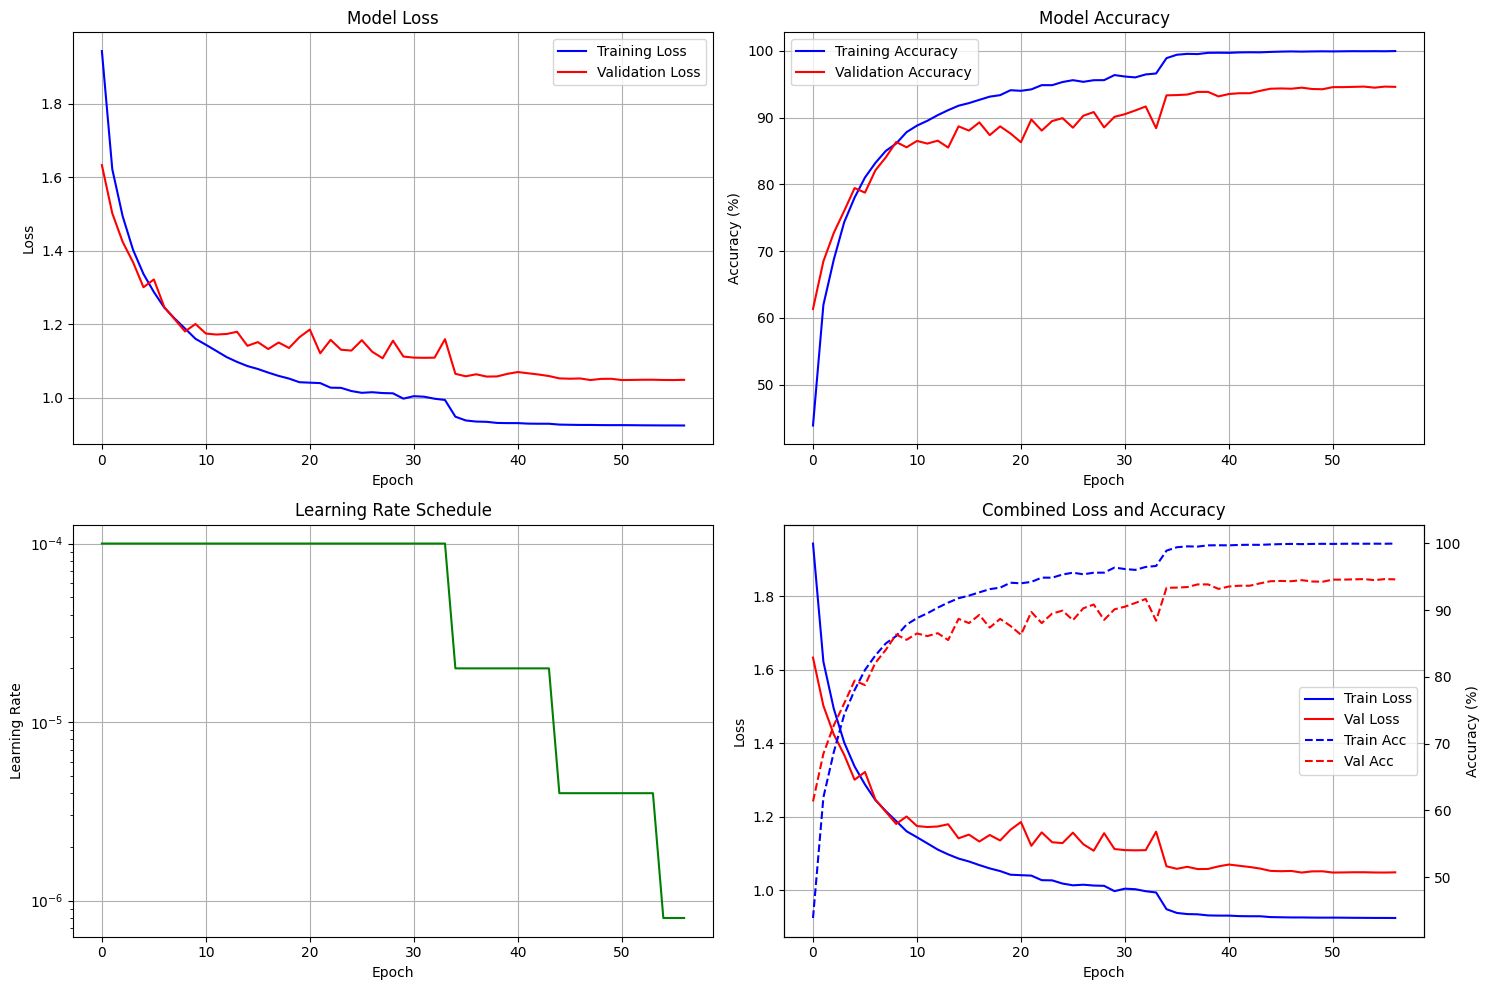

📊 Training plots saved to results\12_class_pytorch/training_history_12class.png
💾 Training history saved to results\12_class_pytorch/training_history_12class.json


In [8]:
# Plot training history and save results
def plot_training_history(history, save_path):
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    # Loss plot
    axes[0, 0].plot(history['train_loss'], label='Training Loss', color='blue')
    axes[0, 0].plot(history['val_loss'], label='Validation Loss', color='red')
    axes[0, 0].set_title('Model Loss')
    axes[0, 0].set_xlabel('Epoch')
    axes[0, 0].set_ylabel('Loss')
    axes[0, 0].legend()
    axes[0, 0].grid(True)
    
    # Accuracy plot
    axes[0, 1].plot(history['train_acc'], label='Training Accuracy', color='blue')
    axes[0, 1].plot(history['val_acc'], label='Validation Accuracy', color='red')
    axes[0, 1].set_title('Model Accuracy')
    axes[0, 1].set_xlabel('Epoch')
    axes[0, 1].set_ylabel('Accuracy (%)')
    axes[0, 1].legend()
    axes[0, 1].grid(True)
    
    # Learning rate plot
    axes[1, 0].plot(history['learning_rates'], color='green')
    axes[1, 0].set_title('Learning Rate Schedule')
    axes[1, 0].set_xlabel('Epoch')
    axes[1, 0].set_ylabel('Learning Rate')
    axes[1, 0].set_yscale('log')
    axes[1, 0].grid(True)
    
    # Combined loss and accuracy
    ax1 = axes[1, 1]
    ax2 = ax1.twinx()
    
    line1 = ax1.plot(history['train_loss'], 'b-', label='Train Loss')
    line2 = ax1.plot(history['val_loss'], 'r-', label='Val Loss')
    line3 = ax2.plot(history['train_acc'], 'b--', label='Train Acc')
    line4 = ax2.plot(history['val_acc'], 'r--', label='Val Acc')
    
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss', color='black')
    ax2.set_ylabel('Accuracy (%)', color='black')
    ax1.set_title('Combined Loss and Accuracy')
    
    # Combine legends
    lines = line1 + line2 + line3 + line4
    labels = [l.get_label() for l in lines]
    ax1.legend(lines, labels, loc='center right')
    
    ax1.grid(True)
    
    plt.tight_layout()
    plt.savefig(save_path / 'training_history_12class.png', dpi=300, bbox_inches='tight')
    plt.show()

# Plot and save training history
plot_training_history(history, RESULTS_PATH)

# Save training history as JSON
with open(RESULTS_PATH / 'training_history_12class.json', 'w') as f:
    json.dump(history, f, indent=4)

print(f"📊 Training plots saved to {RESULTS_PATH}/training_history_12class.png")
print(f"💾 Training history saved to {RESULTS_PATH}/training_history_12class.json")


In [9]:
# Load best model and evaluate
checkpoint = torch.load(MODEL_SAVE_PATH / 'best_model_12class.pth', map_location=device)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

print(f"✅ Best model loaded from epoch {checkpoint['epoch']}")
print(f"📊 Validation accuracy: {checkpoint['val_acc']:.2f}%")
print(f"📊 Validation loss: {checkpoint['val_loss']:.4f}")

# Evaluation function
def evaluate_model(model, test_loader, device, class_names):
    model.eval()
    all_predictions = []
    all_targets = []
    all_probabilities = []
    
    with torch.no_grad():
        progress_bar = tqdm(test_loader, desc='Testing')
        
        for data, target in progress_bar:
            data, target = data.to(device), target.to(device)
            output = model(data)
            probabilities = torch.softmax(output, dim=1)
            _, predicted = torch.max(output, 1)
            
            all_predictions.extend(predicted.cpu().numpy())
            all_targets.extend(target.cpu().numpy())
            all_probabilities.extend(probabilities.cpu().numpy())
    
    # Calculate metrics
    accuracy = accuracy_score(all_targets, all_predictions)
    
    # Classification report
    class_report = classification_report(
        all_targets, all_predictions,
        target_names=class_names,
        digits=4
    )
    
    # Confusion matrix
    cm = confusion_matrix(all_targets, all_predictions)
    
    return {
        'accuracy': accuracy,
        'predictions': all_predictions,
        'targets': all_targets,
        'probabilities': all_probabilities,
        'classification_report': class_report,
        'confusion_matrix': cm
    }

# Evaluate on test set
test_results = evaluate_model(model, test_loader, device, full_dataset.classes)

print(f"\n🎯 Test Results:")
print(f"  Test Accuracy: {test_results['accuracy']*100:.2f}%")
print(f"\n📋 Classification Report:")
print(test_results['classification_report'])


✅ Best model loaded from epoch 48
📊 Validation accuracy: 94.48%
📊 Validation loss: 1.0485


Testing: 100%|██████████| 315/315 [00:17<00:00, 17.70it/s]


🎯 Test Results:
  Test Accuracy: 94.25%

📋 Classification Report:
                precision    recall  f1-score   support

          Cell     0.8190    0.8643    0.8411       199
    Cell-Multi     0.8711    0.8492    0.8601       199
      Cracking     0.9559    0.9466    0.9512       206
         Diode     0.9892    0.9946    0.9919       185
   Diode-Multi     0.9956    1.0000    0.9978       225
      Hot-Spot     0.9912    1.0000    0.9956       226
Hot-Spot-Multi     0.9866    1.0000    0.9933       221
    No-Anomaly     0.9157    0.8624    0.8883       189
Offline-Module     0.9343    0.9476    0.9409       210
     Shadowing     0.9479    0.9756    0.9615       205
       Soiling     0.9819    1.0000    0.9909       217
    Vegetation     0.9067    0.8571    0.8812       238

      accuracy                         0.9425      2520
     macro avg     0.9413    0.9415    0.9411      2520
  weighted avg     0.9424    0.9425    0.9422      2520



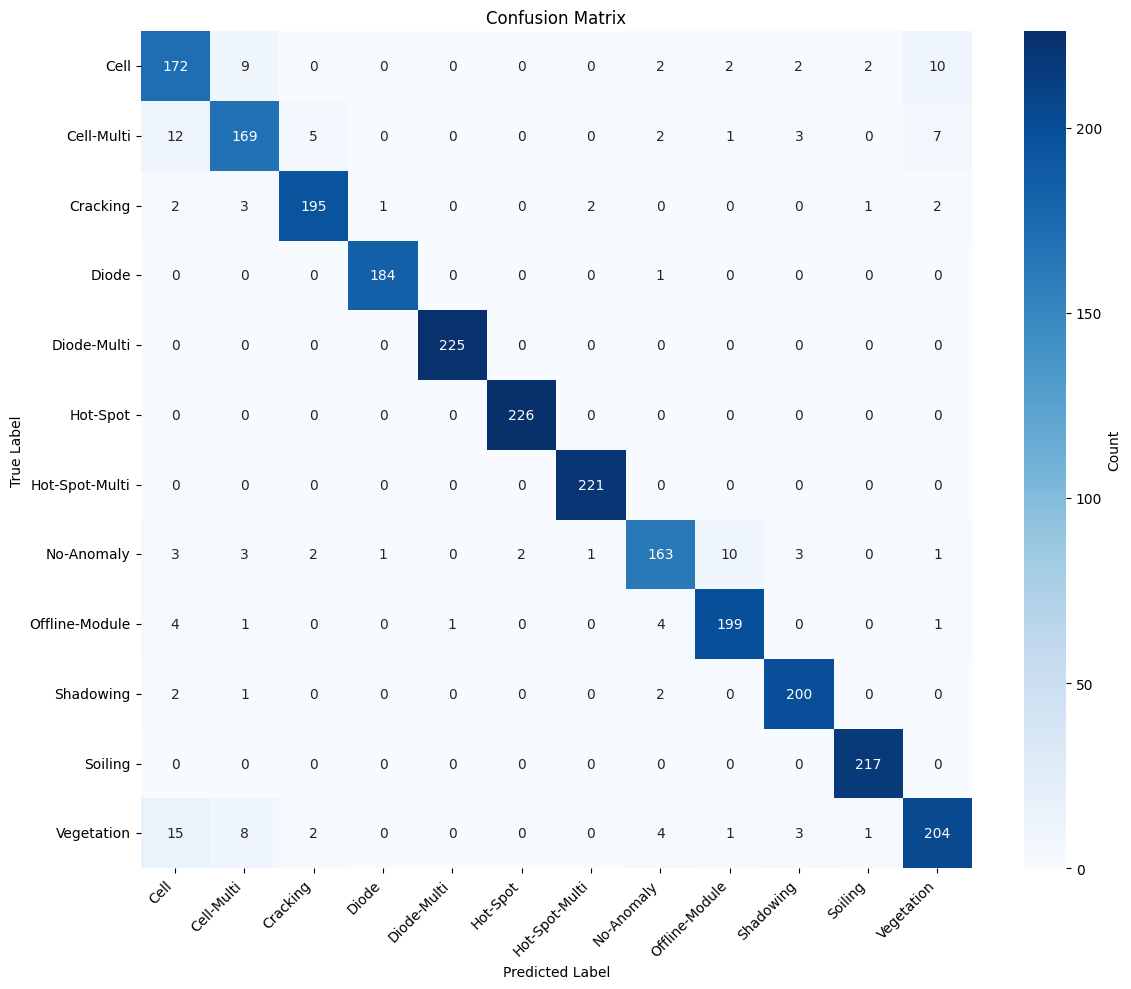

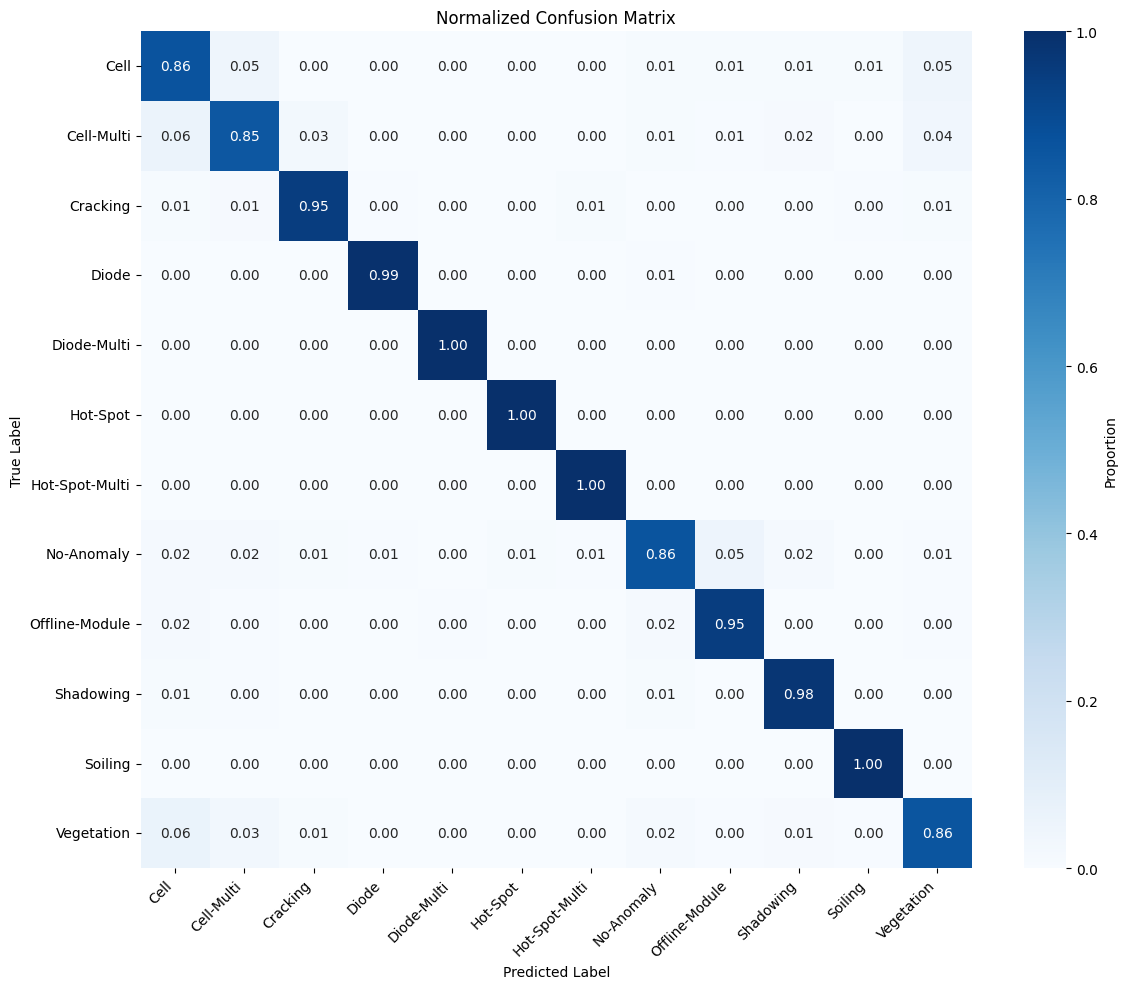

📊 Per-Class Performance:
--------------------------------------------------
Cell           :  86.43% ( 172/ 199)
Cell-Multi     :  84.92% ( 169/ 199)
Cracking       :  94.66% ( 195/ 206)
Diode          :  99.46% ( 184/ 185)
Diode-Multi    : 100.00% ( 225/ 225)
Hot-Spot       : 100.00% ( 226/ 226)
Hot-Spot-Multi : 100.00% ( 221/ 221)
No-Anomaly     :  86.24% ( 163/ 189)
Offline-Module :  94.76% ( 199/ 210)
Shadowing      :  97.56% ( 200/ 205)
Soiling        : 100.00% ( 217/ 217)
Vegetation     :  85.71% ( 204/ 238)
--------------------------------------------------
Overall        :  94.25%


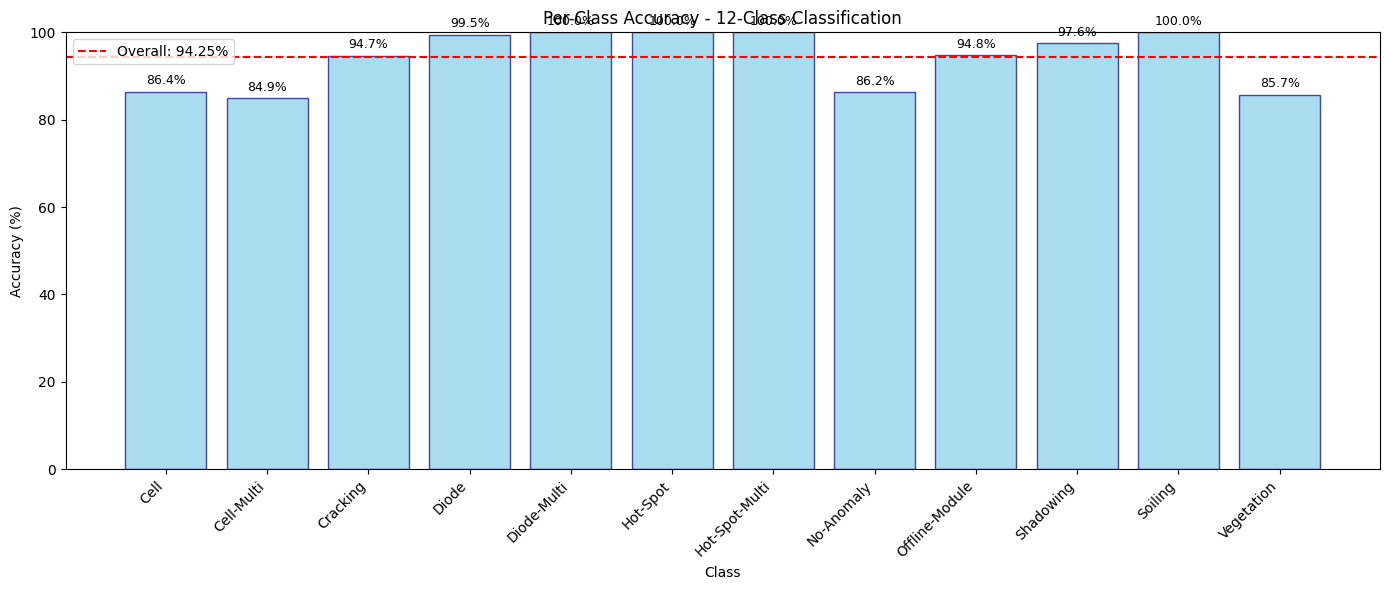

📊 Confusion matrices and analysis plots saved to results\12_class_pytorch/


In [10]:
# Plot confusion matrix and per-class analysis
def plot_confusion_matrix(cm, class_names, save_path, normalize=False):
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        title = 'Normalized Confusion Matrix'
        fmt = '.2f'
    else:
        title = 'Confusion Matrix'
        fmt = 'd'
    
    plt.figure(figsize=(12, 10))
    sns.heatmap(cm, annot=True, fmt=fmt, cmap='Blues',
                xticklabels=class_names, yticklabels=class_names,
                cbar_kws={'label': 'Count' if not normalize else 'Proportion'})
    
    plt.title(title)
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    
    filename = 'confusion_matrix_normalized_12class.png' if normalize else 'confusion_matrix_12class.png'
    plt.savefig(save_path / filename, dpi=300, bbox_inches='tight')
    plt.show()

# Plot both normalized and non-normalized confusion matrices
plot_confusion_matrix(test_results['confusion_matrix'], full_dataset.classes, RESULTS_PATH, normalize=False)
plot_confusion_matrix(test_results['confusion_matrix'], full_dataset.classes, RESULTS_PATH, normalize=True)

# Per-class accuracy analysis
def analyze_per_class_performance(cm, class_names):
    per_class_acc = cm.diagonal() / cm.sum(axis=1)
    
    print("📊 Per-Class Performance:")
    print("-" * 50)
    
    results = []
    for i, (class_name, acc) in enumerate(zip(class_names, per_class_acc)):
        total_samples = cm.sum(axis=1)[i]
        correct_samples = cm.diagonal()[i]
        
        print(f"{class_name:15s}: {acc*100:6.2f}% ({correct_samples:4d}/{total_samples:4d})")
        
        results.append({
            'class': class_name,
            'accuracy': acc,
            'correct': int(correct_samples),
            'total': int(total_samples)
        })
    
    print("-" * 50)
    print(f"{'Overall':15s}: {test_results['accuracy']*100:6.2f}%")
    
    return results

# Analyze per-class performance
per_class_results = analyze_per_class_performance(test_results['confusion_matrix'], full_dataset.classes)

# Create a bar plot for per-class accuracies
plt.figure(figsize=(14, 6))
classes = [r['class'] for r in per_class_results]
accuracies = [r['accuracy'] * 100 for r in per_class_results]

bars = plt.bar(classes, accuracies, color='skyblue', edgecolor='navy', alpha=0.7)
plt.title('Per-Class Accuracy - 12-Class Classification')
plt.xlabel('Class')
plt.ylabel('Accuracy (%)')
plt.xticks(rotation=45, ha='right')
plt.ylim(0, 100)

# Add value labels on bars
for bar, acc in zip(bars, accuracies):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
             f'{acc:.1f}%', ha='center', va='bottom', fontsize=9)

# Add overall accuracy line
plt.axhline(y=test_results['accuracy']*100, color='red', linestyle='--', 
            label=f'Overall: {test_results["accuracy"]*100:.2f}%')
plt.legend()

plt.tight_layout()
plt.savefig(RESULTS_PATH / 'per_class_accuracy_12class.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"📊 Confusion matrices and analysis plots saved to {RESULTS_PATH}/")


In [11]:
# Save comprehensive results and complete notebook
final_results = {
    'model_info': {
        'architecture': 'ViT-B/32',
        'framework': 'PyTorch + TIMM',
        'total_parameters': count_parameters(model),
        'input_shape': HYPERPARAMS['input_shape'],
        'num_classes': HYPERPARAMS['num_classes']
    },
    'training_info': {
        'epochs_trained': len(history['train_loss']),
        'best_epoch': checkpoint['epoch'],
        'hyperparameters': HYPERPARAMS
    },
    'dataset_info': {
        'total_samples': len(full_dataset),
        'train_samples': len(train_dataset),
        'val_samples': len(val_dataset),
        'test_samples': len(test_dataset),
        'classes': full_dataset.classes
    },
    'performance': {
        'test_accuracy': float(test_results['accuracy']),
        'validation_accuracy': float(checkpoint['val_acc'] / 100),
        'validation_loss': float(checkpoint['val_loss']),
        'per_class_accuracy': per_class_results
    },
    'training_history': history,
    'timestamp': datetime.now().isoformat()
}

# Save results
with open(RESULTS_PATH / 'final_results_12class.json', 'w') as f:
    json.dump(final_results, f, indent=4)

# Save classification report
with open(RESULTS_PATH / 'classification_report_12class.txt', 'w') as f:
    f.write("ViT-B/32 12-Class Classification Results\n")
    f.write("=" * 50 + "\n\n")
    f.write(f"Test Accuracy: {test_results['accuracy']*100:.2f}%\n\n")
    f.write("Classification Report:\n")
    f.write(test_results['classification_report'])

# Model inference example
def predict_single_image(model, image_path, transform, device, class_names):
    """Predict class for a single image"""
    from PIL import Image
    
    # Load and preprocess image
    image = Image.open(image_path).convert('RGB')
    image_tensor = transform(image).unsqueeze(0).to(device)
    
    # Make prediction
    model.eval()
    with torch.no_grad():
        output = model(image_tensor)
        probabilities = torch.softmax(output, dim=1)
        predicted_class_idx = torch.argmax(output, dim=1).item()
        predicted_class = class_names[predicted_class_idx]
        confidence = probabilities[0][predicted_class_idx].item()
    
    return {
        'predicted_class': predicted_class,
        'confidence': confidence,
        'probabilities': probabilities.cpu().numpy()[0],
        'class_names': class_names
    }

def show_prediction_example():
    """Show how to use the trained model for inference"""
    print("🔮 Model Inference Example:")
    print("="*50)
    print("To predict on a new image:")
    print("")
    print("```python")
    print("# Load image and predict")
    print("image_path = 'path/to/your/image.jpg'")
    print("result = predict_single_image(")
    print("    model=model,")
    print("    image_path=image_path,")
    print("    transform=val_test_transform,")
    print("    device=device,")
    print("    class_names=full_dataset.classes")
    print(")")
    print("")
    print("print(f'Predicted class: {result[\"predicted_class\"]}')")
    print("print(f'Confidence: {result[\"confidence\"]:.2%}')")
    print("```")
    print("")
    print("📝 Available classes:")
    for i, class_name in enumerate(full_dataset.classes):
        print(f"  {i}: {class_name}")

show_prediction_example()

print(f"\n💾 Results saved to {RESULTS_PATH}/")
print(f"📊 Final test accuracy: {test_results['accuracy']*100:.2f}%")
print(f"🎉 12-Class ViT Training Notebook Complete!")
print(f"📁 Models saved to: {MODEL_SAVE_PATH}")
print(f"📁 Results saved to: {RESULTS_PATH}")
print(f"🚀 Ready for inference and deployment!")


🔮 Model Inference Example:
To predict on a new image:

```python
# Load image and predict
image_path = 'path/to/your/image.jpg'
result = predict_single_image(
    model=model,
    image_path=image_path,
    transform=val_test_transform,
    device=device,
    class_names=full_dataset.classes
)

print(f'Predicted class: {result["predicted_class"]}')
print(f'Confidence: {result["confidence"]:.2%}')
```

📝 Available classes:
  0: Cell
  1: Cell-Multi
  2: Cracking
  3: Diode
  4: Diode-Multi
  5: Hot-Spot
  6: Hot-Spot-Multi
  7: No-Anomaly
  8: Offline-Module
  9: Shadowing
  10: Soiling
  11: Vegetation

💾 Results saved to results\12_class_pytorch/
📊 Final test accuracy: 94.25%
🎉 12-Class ViT Training Notebook Complete!
📁 Models saved to: models\12_class_pytorch
📁 Results saved to: results\12_class_pytorch
🚀 Ready for inference and deployment!
